# 03 — Regression Models and Development Validation
Run after Notebook 02. This notebook reads **only development features**. It compares OLS, Ridge, Lasso and additive Spline + Ridge, selects each family's feature configuration and penalty, and fits four frozen final models.

Training starts with 2021–2022. For each month of 2023–2024, train on all earlier observations and validate on that month. Training preprocessing is refitted inside every fold. Within the validation month, coefficients are frozen and available historical observations provide daily predictors.

The selection score is station-equal MAE within each month, followed by an equal average over the 24 months. Pooled MAE and RMSE are also reported; they use different weights.

## 1. Load development data and predeclare the search

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display

# Locate code/ whether Jupyter starts in the project, code/, or code/script/.
CODE = next((p for base in [Path.cwd(), *Path.cwd().parents]
             for p in [base, base / "code"]
             if (p / "script/01_data_preparation.ipynb").exists()), None)
if CODE is None:
    raise FileNotFoundError("Open this notebook from the project directory.")
DATA = CODE / "data"
RAW = DATA / "raw"
CONFIG = DATA / "config"
PROCESSED = DATA / "processed"
RESULT = CODE / "result"
TABLES = RESULT / "tables"
FIGURES = RESULT / "figures"
MODELS = RESULT / "models"
REPORTS = RESULT / "reports"
for folder in [PROCESSED, TABLES, FIGURES, MODELS, REPORTS]:
    folder.mkdir(parents=True, exist_ok=True)
print("Project directory:", CODE)

Project directory: /Users/yigefeng/Desktop/WashU大三上/SDS4425/Project/code


In [2]:
import itertools
import joblib
from sklearn.preprocessing import SplineTransformer, StandardScaler
from sklearn.linear_model import Lasso
f = pd.read_pickle(PROCESSED / "development_features.pkl.gz")
assert f.role.eq("development").all() and f.target_date.max() < pd.Timestamp("2025-01-01")
spec = json.loads((CONFIG / "feature_spec.json").read_text())
numeric, calendar = spec["numeric"], spec["calendar"]
allfeatures = numeric + calendar
configs = list(itertools.product(spec["lag_candidates"], spec["mean_windows"], spec["std_windows"]))
ridge_grid = [.001, .1, 10.]
lasso_grid = [10., 1., .1, .03, .01, .001, .0001]
protocol = {"feature_configurations": 27, "ridge_grid": ridge_grid, "lasso_grid": lasso_grid,
            "spline": "cubic; 4 training-quantile knots; additive ozone terms; linear calendar terms",
            "extrapolation": "linear", "selection": "monthly station-macro MAE averaged over 24 months",
            "test_used_for_selection": False}
(CONFIG / "model_protocol.json").write_text(json.dumps(protocol, indent=2))
print("Candidates:", len(configs)*(1+len(ridge_grid)+len(lasso_grid)+len(ridge_grid)))

Candidates: 378


## 2. Define training-only transformations and the regression solvers
Ridge minimizes mean squared loss + λ times the sum of squared standardized coefficients. Lasso minimizes one-half mean squared loss + α times the sum of absolute standardized coefficients. Intercepts are not penalized.

Spline + Ridge transforms each selected ozone predictor into cubic basis columns using 4 training-quantile knots. Calendar features stay linear. This coefficient penalty is not the curvature penalty of a classical smoothing spline.

The algorithms use sufficient statistics (XᵀX/n and Xᵀy/n) to avoid fitting the same transformations hundreds of times. Lasso coordinate descent checks its KKT convergence condition and is independently compared with scikit-learn on a reference fit.

In [3]:
def column_indices(config, spline=False):
    lag, mw, sw = config
    names = [f'lag{k}' for k in range(1, lag + 1)] + [f'mean{mw}', f'std{sw}']
    if not spline:
        return [allfeatures.index(n) for n in names] + [len(numeric), len(numeric) + 1]
    return [numeric.index(n) * 5 + j for n in names for j in range(5)] + [len(numeric) * 5, len(numeric) * 5 + 1]

def moment_design(a, b, spline=False):
    spl = None
    if spline:
        spl = SplineTransformer(n_knots=4, degree=3, knots='quantile', include_bias=False, extrapolation='linear')
        x = spl.fit_transform(a[numeric])
        v = spl.transform(b[numeric])
        assert x.shape[1] == len(numeric) * 5
        x = np.column_stack([x, a[['sin', 'cos']]])
        v = np.column_stack([v, b[['sin', 'cos']]])
    else:
        x = a[allfeatures].to_numpy()
        v = b[allfeatures].to_numpy()
    scaler = StandardScaler()
    x = scaler.fit_transform(x)
    v = scaler.transform(v)
    yc = a.target.to_numpy() - a.target.mean()
    cov = x.T @ x / len(x)
    rhs = x.T @ yc / len(x)
    return (x, v, cov, rhs, spl, scaler)

def lasso_from_moments(cov, rhs, alpha, start):
    beta = start.copy()
    diag = np.diag(cov)
    for it in range(20000):
        for j in range(len(beta)):
            r = rhs[j] - cov[j] @ beta + diag[j] * beta[j]
            beta[j] = np.sign(r) * max(abs(r) - alpha, 0) / diag[j] if diag[j] > 1e-14 else 0
        gradient = cov @ beta - rhs
        active = abs(beta) > 1e-12
        kkt = max(float(np.max(abs(gradient[active] + alpha * np.sign(beta[active])))) if active.any() else 0, float(np.max(np.maximum(abs(gradient[~active]) - alpha, 0))) if (~active).any() else 0)
        if kkt < 1e-08:
            return (beta, kkt)
    raise RuntimeError('Lasso failed KKT convergence')

## 3. Run 24 expanding-window validation folds

In [4]:
rows = []
audits = []
for month in pd.date_range('2023-01-01', '2024-12-01', freq='MS'):
    a = f[f.target_date < month]
    b = f[(f.target_date >= month) & (f.target_date < month + pd.offsets.MonthBegin(1))]
    assert a.target_date.max() < b.target_date.min()
    y = b.target.to_numpy()
    mu = a.target.mean()
    sid, inv = np.unique(b.station_id, return_inverse=True)
    ns = np.bincount(inv)
    base = b.lag1.to_numpy() - y
    for spline in [False, True]:
        x, v, cov, rhs, spl, scaler = moment_design(a, b, spline)
        for config in configs:
            lag, mw, sw = config
            ix = column_indices(config, spline)
            C = cov[np.ix_(ix, ix)]
            r = rhs[ix]
            vv = v[:, ix]
            solutions = []
            if spline:
                solutions = [('Spline_Ridge', p, np.linalg.solve(C + p * np.eye(len(ix)), r)) for p in ridge_grid]
            else:
                solutions = [('OLS', 0.0, np.linalg.lstsq(C, r, rcond=1e-12)[0])] + [('Ridge', p, np.linalg.solve(C + p * np.eye(len(ix)), r)) for p in ridge_grid]
                start = np.zeros(len(ix))
                for p in lasso_grid:
                    start, kkt = lasso_from_moments(C, r, p, start)
                    solutions.append(('Lasso', p, start.copy()))
                    if month == pd.Timestamp('2023-01-01') and config == (1, 7, 7) and (p == 0.01):
                        direct = Lasso(alpha=p, fit_intercept=False, tol=1e-10, max_iter=20000).fit(x[:, ix], a.target.to_numpy() - mu)
                        assert np.allclose(vv @ start, direct.predict(vv), atol=1e-05)
            for family, p, coef in solutions:
                err = mu + vv @ coef - y
                ae = abs(err)
                macro = np.mean(np.bincount(inv, weights=ae) / ns)
                rows.append({'family': family, 'lag': lag, 'mean_window': mw, 'std_window': sw, 'parameter': p, 'month': str(month.date()), 'macro_mae': macro, 'n': len(y), 'sum_abs_error': ae.sum(), 'sum_squared_error': (err ** 2).sum(), 'baseline_abs_error': abs(base).sum(), 'nonzero': int((abs(coef) > 1e-08).sum())})
        del x, v, cov, rhs
    audits.append({'month': str(month.date()), 'train_end': str(a.target_date.max().date()), 'n_train': len(a), 'n_valid': len(b), 'stations': len(sid)})
    pd.DataFrame(rows).to_csv(TABLES / 'monthly_validation.csv', index=False)
    print('Completed validation', str(month.date()), flush=True)

Completed validation 2023-01-01


Completed validation 2023-02-01


Completed validation 2023-03-01


Completed validation 2023-04-01


Completed validation 2023-05-01


Completed validation 2023-06-01


... (14 outputs left out)

Completed validation 2024-09-01


Completed validation 2024-10-01


Completed validation 2024-11-01


Completed validation 2024-12-01


## 4. Select one configuration per model family
Select only from development validation. All 378 candidates must have the same 24 validation months and sample counts. Save the decisions before the evaluation notebook is run.

In [5]:
m = pd.DataFrame(rows)
keys = ['family', 'lag', 'mean_window', 'std_window', 'parameter']
rank = m.groupby(keys).agg(selection_macro_mae=('macro_mae', 'mean'), months=('month', 'size'), n=('n', 'sum'), ae=('sum_abs_error', 'sum'), se=('sum_squared_error', 'sum'), baseline_ae=('baseline_abs_error', 'sum')).reset_index()
rank['pooled_mae'] = rank.ae / rank.n
rank['pooled_rmse'] = np.sqrt(rank.se / rank.n)
rank['improvement_pct'] = 100 * (1 - rank.ae / rank.baseline_ae)
rank = rank.sort_values(['selection_macro_mae'] + keys)
rank.to_csv(TABLES / 'all_candidate_ranking.csv', index=False)
best = rank.groupby('family', sort=False).head(1)
best.to_csv(TABLES / 'selected_models.csv', index=False)
assert len(rank) == 378 and rank.months.eq(24).all() and (len(best) == 4)
assert m.groupby('month').n.nunique().eq(1).all()
(TABLES / 'selection_locked_before_test.json').write_text(json.dumps(best[keys + ['selection_macro_mae']].to_dict('records'), indent=2))
print('DEVELOPMENT SELECTED\n' + best.to_string(index=False), flush=True)
pd.DataFrame(audits).to_csv(TABLES / "fold_audit.csv", index=False)
display(best[["family", "lag", "mean_window", "std_window", "parameter", "selection_macro_mae"]])

DEVELOPMENT SELECTED
      family  lag  mean_window  std_window  parameter  selection_macro_mae  months      n           ae           se  baseline_ae  pooled_mae  pooled_rmse  improvement_pct
       Lasso    7           28          14      0.010             5.554470      24 477250 2.716549e+06 2.690045e+07    2992848.0    5.692087     7.507698         9.231987
         OLS    7           28          14      0.000             5.554675      24 477250 2.716750e+06 2.690429e+07    2992848.0    5.692510     7.508234         9.225246
       Ridge    7           28          14      0.001             5.554722      24 477250 2.716817e+06 2.690368e+07    2992848.0    5.692651     7.508149         9.223005
Spline_Ridge    7           28          14      0.001             5.556171      24 477250 2.718179e+06 2.690856e+07    2992848.0    5.695503     7.508830         9.177516


,family,lag,mean_window,std_window,parameter,selection_macro_mae
177,Lasso,7,28,14,0.010,5.554470
214,OLS,7,28,14,0.000,5.554675
291,Ridge,7,28,14,0.001,5.554722
372,Spline_Ridge,7,28,14,0.001,5.556171


## 5. Refit each selected configuration on all 2021–2024 development data
Refit the scaler, spline transformer and coefficients on the complete development period. The saved objects contain all transformations needed for prediction; Notebook 04 must not refit them.

In [6]:
coefficients = []
for _, win in best.iterrows():
    family = win.family
    lag, mw, sw = int(win.lag), int(win.mean_window), int(win.std_window)
    penalty = float(win.parameter)
    names = [f"lag{k}" for k in range(1,lag+1)] + [f"mean{mw}", f"std{sw}"]
    x = f[names].to_numpy()
    spline = None
    labels = names + calendar
    if family == "Spline_Ridge":
        spline = SplineTransformer(n_knots=4, degree=3, knots="quantile", include_bias=False, extrapolation="linear")
        x = spline.fit_transform(x)
        labels = [f"basis_{k}" for k in range(x.shape[1])] + calendar
    x = np.column_stack([x, f[calendar]])
    scaler = StandardScaler()
    x = scaler.fit_transform(x)
    intercept = f.target.mean()
    cov = x.T @ x / len(x)
    rhs = x.T @ (f.target.to_numpy()-intercept) / len(x)
    if family == "OLS":
        coef = np.linalg.lstsq(cov, rhs, rcond=1e-12)[0]
    elif family == "Lasso":
        coef, kkt = lasso_from_moments(cov, rhs, penalty, np.zeros(len(rhs)))
    else:
        coef = np.linalg.solve(cov + penalty*np.eye(len(rhs)), rhs)
    model = {"family": family, "selected": win.to_dict(), "numeric_features": names,
             "calendar": calendar, "spline": spline, "scaler": scaler, "coef": coef,
             "intercept": intercept, "train_end": str(f.target_date.max()),
             "training_station_ids": sorted(f.station_id.unique())}
    joblib.dump(model, MODELS / f"{family}_frozen.joblib")
    for name, value in zip(labels, coef):
        coefficients.append({"family": family, "feature": name, "standardized_coefficient": value,
                             "nonzero": bool(abs(value)>1e-8)})
pd.DataFrame(coefficients).to_csv(TABLES / "coefficients.csv", index=False)
audit = {"candidate_count": len(rank), "folds": 24, "train_rows": len(f), "train_stations": f.station_id.nunique(),
         "validation_rows": int(rank.n.iloc[0]), "test_used": False, "checks_passed": True}
(TABLES / "training_audit.json").write_text(json.dumps(audit, indent=2))

168

## 6. Plot development results

In [7]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)

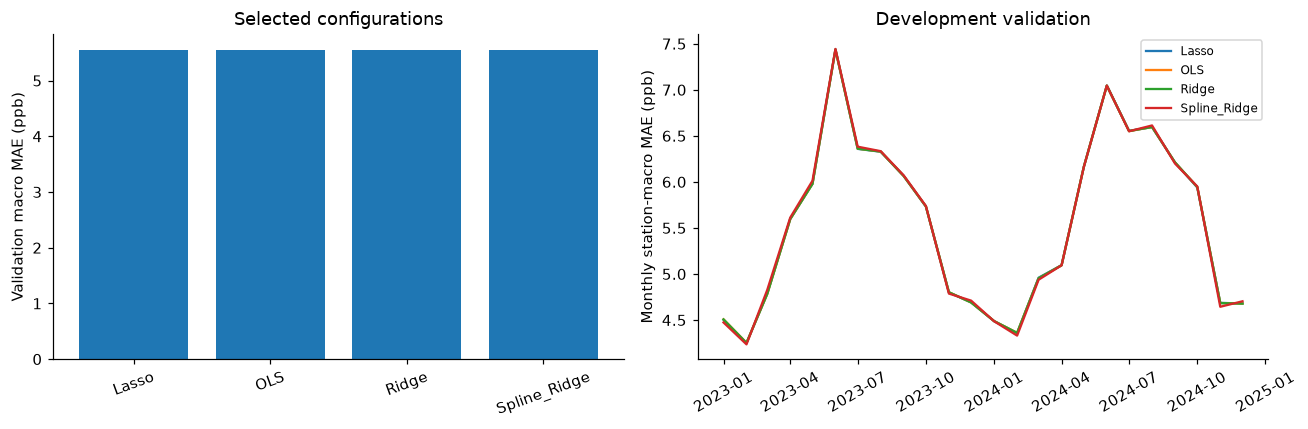

Four frozen models saved. Next: run 04_out_of_sample_evaluation.ipynb


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(best.family, best.selection_macro_mae)
axes[0].set(ylabel="Validation macro MAE (ppb)", title="Selected configurations")
axes[0].tick_params(axis="x", rotation=20)
selected_months = m.merge(best[keys], on=keys, validate="many_to_one")
for family, group in selected_months.groupby("family"):
    axes[1].plot(pd.to_datetime(group.month), group.macro_mae, label=family)
axes[1].set(ylabel="Monthly station-macro MAE (ppb)", title="Development validation")
axes[1].legend(fontsize=8)
axes[1].tick_params(axis="x", rotation=30)
save_figure(fig, "04_development_validation.png")
print("Four frozen models saved. Next: run 04_out_of_sample_evaluation.ipynb")